## Evaluation metrics

In the binary classification module we trained a logistic regression model that predicts customer churn . But how do we know if it's good , accurate and correct ?

We will use metrics to evaluate the model 

A metric is a function that compares the predictions with the actual values and outputs a single number that tells how good the predictions are.

That is all a metric is: predictions go in, the true values go in, and one number comes out. Different metrics look at different aspects of the predictions, and picking the right one for the problem is the topic of this whole module.






In [33]:
import pandas as pd # To import pandas library for data manipulation and analysis
import numpy as np # To import numpy library for numerical computations

import matplotlib.pyplot as plt # To import matplotlib library for data visualization
import seaborn as sns # To import seaborn library for statistical data visualization

# To display plots inline in Jupyter Notebook
%matplotlib inline 

In [34]:
from sklearn.model_selection import train_test_split # To import the train_test_split function from scikit-learn for splitting the dataset into training and testing sets
from sklearn.feature_extraction import DictVectorizer # To import the DictVectorizer class from scikit-learn for converting feature dictionaries into numerical feature vectors
from sklearn.linear_model import LogisticRegression # To import the LogisticRegression class from scikit-learn for building a logistic regression model

We will use the same dataset as in the churn model for the telcom company 
Dataset used in this project is donwloded from Kaggle , URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

In [35]:
df = pd.read_csv('/workspaces/ML-Projects/Classification/WA_Fn-UseC_-Telco-Customer-Churn.csv') # To read the CSV file containing customer churn data into a pandas DataFrame
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


We Will do the necessary data preparation and setting up the validation framework


In [36]:
df.columns = df.columns.str.lower().str.replace(' ', '_') # To convert all column names to lowercase and replace spaces with underscores for consistency and easier access

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index) # To create a list of column names that have data type 'object', which typically indicates categorical variables

for col in categorical_columns: # To iterate over each column name in the list of categorical columns
    df[col] = df[col].str.lower().str.replace(' ', '_') # To convert all string values in the column to lowercase and replace spaces with underscores for consistency and easier analysis
    
df

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.5,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-resvb,male,0,yes,yes,24,yes,yes,dsl,yes,...,yes,yes,yes,yes,one_year,yes,mailed_check,84.80,1990.5,no
7039,2234-xaduh,female,0,yes,yes,72,yes,yes,fiber_optic,no,...,yes,no,yes,yes,one_year,yes,credit_card_(automatic),103.20,7362.9,no
7040,4801-jzazl,female,0,yes,yes,11,no,no_phone_service,dsl,yes,...,no,no,no,no,month-to-month,yes,electronic_check,29.60,346.45,no
7041,8361-ltmkd,male,1,yes,no,4,yes,yes,fiber_optic,no,...,no,no,no,no,month-to-month,yes,mailed_check,74.40,306.6,yes


In [37]:
tc = pd.to_numeric(df.totalcharges, errors='coerce') # To convert the 'totalcharges' column to numeric type, coercing any errors (e.g., non-numeric values) to NaN

df.totalcharges = df.totalcharges.fillna(0) # To fill any NaN values in the 'totalcharges' column with 0, ensuring that there are no missing values in this numeric column

df.churn = (df.churn == 'yes').astype(int) # To convert the 'churn' column to a binary format where 'yes' is represented as 1 and 'no' as 0, making it suitable for machine learning models that require numerical input.



In [38]:
df_full_train , df_test = train_test_split(df, test_size = 0.2 , random_state = 1) # To split the DataFrame 'df' into training and testing sets, with 20% of the data allocated for testing and a random state of 1 for reproducibility , so wehen execute the code you will get the same result. This function returns four outputs: X_train, X_test, y_train, y_test.
df_train , df_val = train_test_split(df_full_train, test_size = 0.25 , random_state = 1) # To further split the training set into a smaller training set and a validation set, with 25% of the data allocated for validation. This allows for model evaluation during training.

df_train = df_train.reset_index(drop = True )
df_val = df_val.reset_index(drop = True ) 
df_test = df_test.reset_index(drop = True ) # To reset the index of the training, validation, and testing DataFrames, dropping the old index. This is useful for ensuring that the indices are sequential and start from 0, which can help avoid confusion during analysis and modeling.

y_train = df_train.churn.values # To extract the target variable 'churn' from the training set and convert it to a NumPy array for model training
y_val = df_val.churn.values # To extract the target variable 'churn' from the validation set and convert it to a NumPy array for model evaluation
y_test = df_test.churn.values # To extract the target variable 'churn' from the testing set and convert it to a NumPy array for final model evaluation

del df_train['churn'] # To remove the 'churn' column from the training DataFrame, as it has already been extracted into the y_train array and is no longer needed in the feature set.
del df_val['churn'] # To remove the 'churn' column from the validation DataFrame, as it has already been extracted into the y_val array and is no longer needed in the feature set.
del df_test['churn'] # To remove the 'churn' column from the testing DataFrame, as it has already been extracted into the y_test array and is no



In [39]:
numerical = ['tenure', 'monthlycharges', 'totalcharges'] # To create a list of column names that represent numerical features in the dataset, which will be used for model training and evaluation. These features are typically continuous variables that can take on a wide range of values.

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
] # To create a list of column names that represent categorical features in the dataset, which will be used for model training and evaluation. These features are typically discrete variables that can take on a limited number of values or categories.

In [40]:
dv = DictVectorizer(sparse=False) # To create an instance of the DictVectorizer class, which will be used to convert feature dictionaries into numerical feature vectors. The parameter sparse=False indicates that the output will be a dense array rather than a sparse matrix.

train_dict = df_train[categorical + numerical].to_dict(orient='records') # To convert the training DataFrame into a list of dictionaries, where each dictionary represents a single record (row) in the DataFrame. The 'orient' parameter is set to 'records', which means that each dictionary will contain key-value pairs corresponding to the column names and their respective values for that record.
X_train = dv.fit_transform(train_dict) # To fit the DictVectorizer to the training data and transform the list of dictionaries into a numerical feature matrix (X_train). This matrix will be used as input for model training.

model = LogisticRegression() # To create an instance of the LogisticRegression class, which will be used to build a logistic regression model for predicting customer churn based on the input features.
model.fit(X_train, y_train) # To fit the logistic regression model to the training data (X_train and y_train). This process involves finding the optimal coefficients for the model that minimize the difference between the predicted and actual values of the target variable (churn).




/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [41]:
val_dict = df_val[categorical + numerical].to_dict(orient='records') # To convert the validation DataFrame into a list of dictionaries, where each dictionary represents a single record (row) in the DataFrame. The 'orient' parameter is set to 'records', which means that each dictionary will contain key-value pairs corresponding to the column names and their respective values for that record.
X_val = dv.transform(val_dict) # To transform the validation data using the previously fitted DictVectorizer (dv). This converts the list of dictionaries into a numerical feature matrix (X_val) that can be used for model evaluation.

y_pred = model.predict_proba(X_val)[:, 1] # To generate predicted probabilities for the positive class (churn) using the logistic regression model. The predict_proba method returns an array of probabilities for each class, and [:, 1] selects the probabilities for the positive class (churn). These probabilities will be used to make binary predictions based on a threshold.
churn_decision = (y_pred >= 0.5) # To create a binary array (churn_decision) that indicates whether each predicted probability is greater than or equal to 0.5. If the predicted probability is greater than or equal to 0.5, it is classified as churn (1), otherwise it is classified as no churn (0). This threshold can be adjusted based on the desired sensitivity and specificity of the model.
(y_val == churn_decision).mean() # To calculate the accuracy of the model's predictions on the validation set by comparing the true labels (y_val) with the predicted binary decisions (churn_decision). The mean() function computes the proportion of correct predictions, which represents the model's accuracy.

np.float64(0.8034066713981547)

## Accuracy

- Evaluate the model on different thresholds
- Check the accuracy of dummy baselines



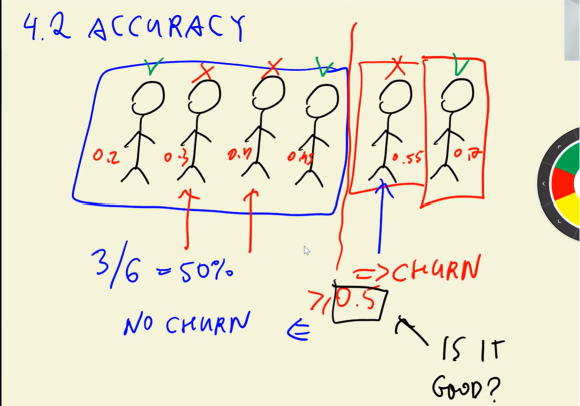


In [42]:
(y_val == churn_decision).sum() # To calculate the total number of correct predictions made by the model on the validation set by comparing the true labels (y_val) with the predicted binary decisions (churn_decision). The sum() function counts the number of instances where the predicted decision matches the actual label, providing insight into the model's performance in terms of correctly classified cases.

np.int64(1132)

In [43]:
(y_val == churn_decision).mean() # To calculate the accuracy of the model's predictions on the validation set by comparing the true labels (y_val) with the predicted binary decisions (churn_decision). The mean() function computes the proportion of correct predictions, which represents the model's accuracy.

np.float64(0.8034066713981547)

In [44]:
1132 / 1409 # tO calculate the accuracy of the model's predictions on the validation set by dividing the total number of correct predictions (1132) by the total number of instances in the validation set (1409). This provides a simple way to compute the accuracy without using built-in functions.

0.8034066713981547

The treshhold we used is 0.5 , what if we change it to know if it's good or no to see if will imporve the accuracy 

In [45]:
from sklearn.metrics import accuracy_score # To import the accuracy_score function from scikit-learn, which will be used to calculate the accuracy of the model's predictions on the validation set by comparing the true labels (y_val) with the predicted binary decisions (churn_decision). This function provides a convenient way to compute accuracy without manually calculating it.

In [46]:
accuracy_score(y_val, y_pred >= 0.5) # To calculate the accuracy of the model's predictions on the validation set using the accuracy_score function from scikit-learn. This function compares the true labels (y_val) with the predicted binary decisions (y_pred >= 0.5) and returns the proportion of correct predictions, providing a straightforward way to assess model performance.

0.8034066713981547

In [47]:
thresholds = np.linspace(0, 1, 21) # To create an array of threshold values ranging from 0 to 1, with 21 evenly spaced points. These thresholds will be used to evaluate the model's performance at different decision boundaries for classifying churn.

scores = [] # To create an empty list to store the accuracy scores for each threshold value.

for t in thresholds: # To iterate over each threshold value in the array of thresholds
    
    score = accuracy_score(y_val, y_pred >= t) # To calculate the accuracy score for the current threshold value (t) by comparing the true labels (y_val) with the predicted binary decisions (y_pred >= t). The accuracy_score function computes the proportion of correct predictions, providing insight into how well the model performs at this specific threshold.
    print('%.2f %.3f' % (t, score)) # To print the current threshold value (t) and the corresponding accuracy score (score) formatted to two decimal places for the threshold and three decimal places for the score. This provides a clear view of how the model's accuracy changes with different thresholds.
    scores.append(score) # To append the calculated accuracy score for the current threshold value (t) to a list or array (score). This allows for tracking the model's performance across different thresholds, which can be useful for selecting an optimal threshold based on the desired balance between sensitivity and specificity.

0.00 0.274
0.05 0.534
0.10 0.603
0.15 0.644
0.20 0.696
0.25 0.730
0.30 0.759
0.35 0.771
0.40 0.786
0.45 0.801
0.50 0.803
0.55 0.806
0.60 0.801
0.65 0.793
0.70 0.774
0.75 0.747
0.80 0.738
0.85 0.727
0.90 0.726
0.95 0.726
1.00 0.726


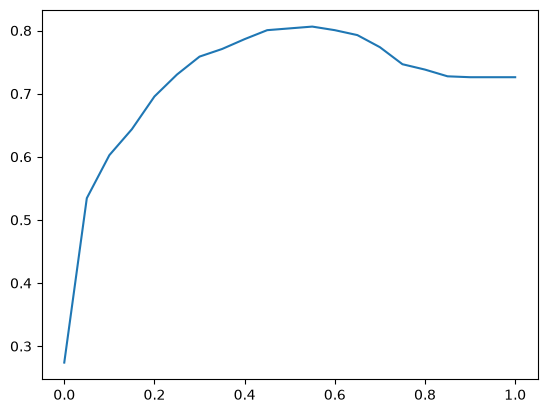

In [48]:
plt.plot(thresholds, scores) # To create a line plot of the accuracy scores against the corresponding threshold values. This visualization helps to identify how the model's accuracy changes with different decision thresholds, allowing for better selection of an optimal threshold for classification.

Any value over 1.0 is churning 

In [49]:
from collections import Counter # To import the Counter class from the collections module, which will be used to count the occurrences of each class in the target variable (churn) for further analysis and understanding of class distribution.

In [50]:
Counter (y_pred >= 1.0) # To count the occurrences of each class (True/False) in the binary predictions made by the model when using a threshold of 1.0. This provides insight into how many instances are classified as churn (True) versus no churn (False) at this extreme threshold, which can help in understanding the model's behavior and class distribution.

Counter({np.False_: 1409})

In [53]:
1 - y_val.mean() # To calculate the proportion of instances in the validation set that are classified as no churn (0) by subtracting the mean of the true labels (y_val) from 1. This provides insight into the class distribution of the target variable, indicating how many instances belong to the negative class (no churn) compared to the positive class (churn).

np.float64(0.7260468417317246)